# 01 - Exploratory analysis of BCI Competition IV 2a

Goal: understand the signal before modelling it, and use what we see to justify
the preprocessing choices (frequency band, time window) used by every model.

**Only the training session (`0train`) is used here.** The band and window are
modelling decisions; choosing them after looking at the test session would be a
subtle form of test-set leakage.

Trial timeline (time relative to the cue, which is how every figure is aligned):

| t (s) | event |
|---|---|
| -2.0 | fixation cross + warning tone |
| 0.0 | cue: arrow left / right / down / up (left hand, right hand, feet, tongue) |
| 0.0 - 4.0 | motor imagery |
| 4.0 | fixation cross disappears, break |

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne, moabb

from src.data import BNCI2014_001, CLASSES, SESSION_TRAIN, SUBJECTS, EpochConfig, load_epochs

print("mne", mne.__version__, "| moabb", moabb.__version__)

COLORS = {"left_hand": "#2a78d6", "right_hand": "#eb6834", "feet": "#1baf7a", "tongue": "#eda100"}
LABELS = {"left_hand": "Left hand", "right_hand": "Right hand", "feet": "Feet", "tongue": "Tongue"}
INK, MUTED, GRID = "#1f1f1e", "#6b6b68", "#e4e4e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 2.0, "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})

mne 1.13.2 | moabb 1.7.2


## 1. Dataset overview

9 subjects, 2 sessions recorded on different days, 6 runs x 48 trials per session
(12 per class per run), 22 EEG channels + 3 EOG channels at 250 Hz. The table
comes from `python -m src.data` (saved in `results/data_summary.csv`).

In [2]:
summary = pd.read_csv(ROOT / "results" / "data_summary.csv")
summary

,subject,session,n_runs,n_trials,left_hand,right_hand,feet,tongue
0,1,0train,6,288,72,72,72,72
1,1,1test,6,288,72,72,72,72
2,2,0train,6,288,72,72,72,72
3,2,1test,6,288,72,72,72,72
4,3,0train,6,288,72,72,72,72
5,3,1test,6,288,72,72,72,72
6,4,0train,6,288,72,72,72,72
7,4,1test,6,288,72,72,72,72
8,5,0train,6,288,72,72,72,72
9,5,1test,6,288,72,72,72,72


## 2. Electrode montage

The 22 electrodes cover the sensorimotor cortex. **C3** lies over the left motor
cortex (hand area), **C4** over the right, and **Cz** over the midline, where the
feet are represented (the leg area sits deep in the medial fissure).

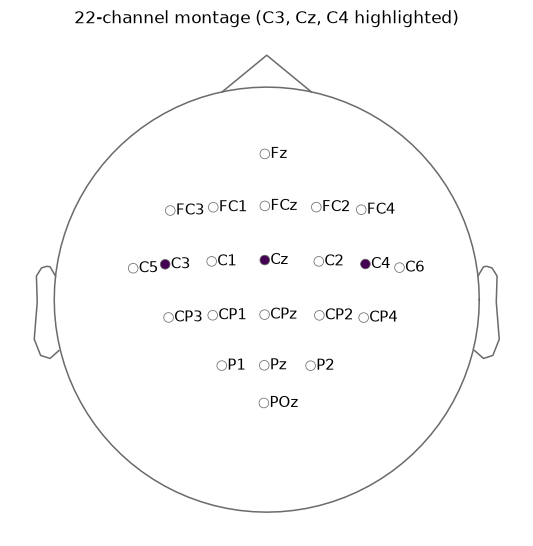

In [3]:
raw_dict = BNCI2014_001().get_data(subjects=[1])[1][SESSION_TRAIN]
raw = raw_dict[sorted(raw_dict)[0]].copy()
eeg_info = raw.copy().pick("eeg").info

fig, ax = plt.subplots(figsize=(6.0, 6.0))
mne.viz.plot_sensors(eeg_info, kind="topomap", show_names=True, axes=ax, show=False,
                     ch_groups=[[eeg_info.ch_names.index(c) for c in ("C3", "Cz", "C4")]],
                     pointsize=40, linewidth=0.5)
ax.set_title("22-channel montage (C3, Cz, C4 highlighted)")
fig.savefig(FIG / "eda_montage.png")
plt.show()

## 3. Raw signals

Subject 1, first training run, 12 s starting at the first trial. Left: the
signal as recorded (0.5-100 Hz, 50 Hz notch). Right: the same data band-passed
to 8-30 Hz (mu + beta), the band used by the CSP baseline. EOG1 is shown to make
blinks / eye movements visible; it is **not** used as a model input.

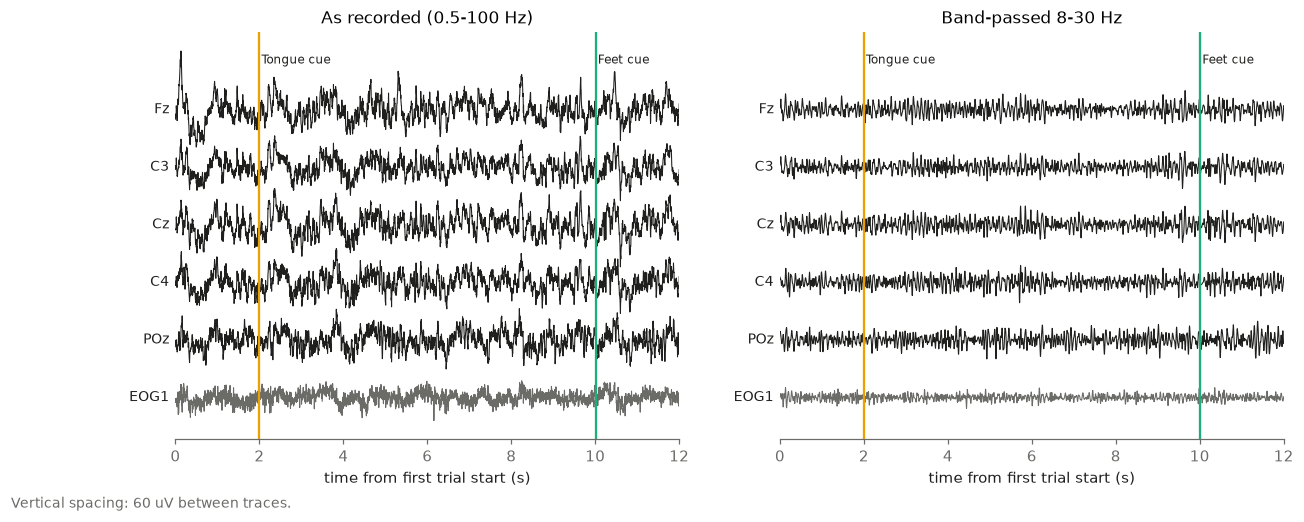

In [4]:
events = mne.find_events(raw, verbose=False)
inv_ev = {v: k for k, v in BNCI2014_001().event_id.items()}
sf = raw.info["sfreq"]
# MOABB stim events mark the trial start (t = 0); the cue comes 2 s later.
t0 = events[0, 0] / sf                    # first trial start
win = (t0, t0 + 12.0)
chans = ["Fz", "C3", "Cz", "C4", "POz", "EOG1"]

def stack_plot(ax, r, title):
    seg = r.copy().pick(chans).crop(*win)
    data = seg.get_data() * 1e6
    t = seg.times + win[0] - t0
    offset = 60.0
    for i, (ch, x) in enumerate(zip(chans, data)):
        ax.plot(t, x - x.mean() - i * offset, color=INK if ch != "EOG1" else MUTED, lw=0.7)
        ax.text(t[0] - 0.15, -i * offset, ch, ha="right", va="center", color=INK, fontsize=9)
    for ev in events:
        tc = ev[0] / sf + 2.0 - t0          # cue time on this axis
        if 0 <= tc <= 12:
            ax.axvline(tc, color=COLORS[inv_ev[ev[2]]], lw=1.5)
            ax.text(tc + 0.05, offset * 0.8, LABELS[inv_ev[ev[2]]] + " cue", fontsize=8, color=INK)
    ax.set_yticks([]); ax.grid(False); ax.spines["left"].set_visible(False)
    ax.set_xlabel("time from first trial start (s)")
    ax.set_title(title)
    ax.set_xlim(t[0], t[-1])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
stack_plot(axes[0], raw, "As recorded (0.5-100 Hz)")
stack_plot(axes[1], raw.copy().filter(8, 30, picks=["eeg", "eog"], verbose=False), "Band-passed 8-30 Hz")
fig.text(0.01, -0.02, "Vertical spacing: 60 uV between traces.", fontsize=9, color=MUTED)
fig.savefig(FIG / "eda_raw_signals.png")
plt.show()

The raw trace is dominated by slow drifts and large low-frequency components.
After band-passing, the ongoing 8-30 Hz oscillations become visible. There are
no class differences you can see by eye in single trials: the motor-imagery
signal is a small change in oscillatory *power*, which is why the analysis below
averages over many trials.

## 4. Epoching for the exploratory analysis

For EDA only, we take long, broadband epochs: 1-45 Hz, from -2.5 s to +5.0 s
around the cue. The padding before -1.5 s and after +4 s exists only to absorb
the edge effects of the wavelet transform; the figures are cropped. The models
use different settings (see `configs/`).

In [5]:
EDA_CFG = EpochConfig(fmin=1.0, fmax=45.0, tmin=-2.5, tmax=5.0)
FREQS = np.arange(4.0, 41.0, 1.0)
N_CYCLES = np.maximum(FREQS / 2.0, 3.0)
BASELINE = (-1.5, -0.5)                  # fixation period, before the cue

psd_by_class, tfr_by_class, n_trials = {}, {}, {}
for s in SUBJECTS:
    epochs, y, meta = load_epochs(s, EDA_CFG)
    epochs = epochs[(meta["session"] == SESSION_TRAIN).to_numpy()]
    y = y[(meta["session"] == SESSION_TRAIN).to_numpy()]
    n_trials[s] = len(y)
    for k, cls in enumerate(CLASSES):
        ep = epochs[np.where(y == k)[0]]
        spec = ep.compute_psd(method="welch", fmin=2, fmax=40, tmin=0.5, tmax=4.0,
                              n_fft=500, n_per_seg=250, n_overlap=125, verbose=False)
        psd_by_class.setdefault(cls, []).append(spec.get_data().mean(axis=0))  # (ch, f)
        tfr = ep.compute_tfr("morlet", freqs=FREQS, n_cycles=N_CYCLES, average=True,
                             return_itc=False, decim=5, verbose=False)
        tfr.apply_baseline(BASELINE, mode="percent", verbose=False)       # per subject
        tfr_by_class.setdefault(cls, []).append(tfr.get_data())            # (ch, f, t)
    print(f"subject {s}: {len(y)} training trials")

psd_freqs = spec.freqs
tfr_times = tfr.times
ch_names = epochs.ch_names
info = epochs.info
ga_tfr = {c: np.mean(v, axis=0) * 100 for c, v in tfr_by_class.items()}   # percent change
ga_psd = {c: np.mean(v, axis=0) for c, v in psd_by_class.items()}
assert all(n == 288 for n in n_trials.values()), n_trials

subject 1: 288 training trials


subject 2: 288 training trials


subject 3: 288 training trials


subject 4: 288 training trials


subject 5: 288 training trials


subject 6: 288 training trials


subject 7: 288 training trials


subject 8: 288 training trials


subject 9: 288 training trials


## 5. Power spectrum by class

Welch PSD of the imagery period (0.5-4.0 s after the cue), averaged over trials
and then over the 9 subjects. All classes share the 1/f background and a peak
in the **mu band (8-13 Hz)**. The class differences sit almost entirely in the mu
band and, less clearly, around 20 Hz (beta). Note that feet and tongue imagery
have *more* mu power over C3/C4 than the two hand classes: section 6 explains why.

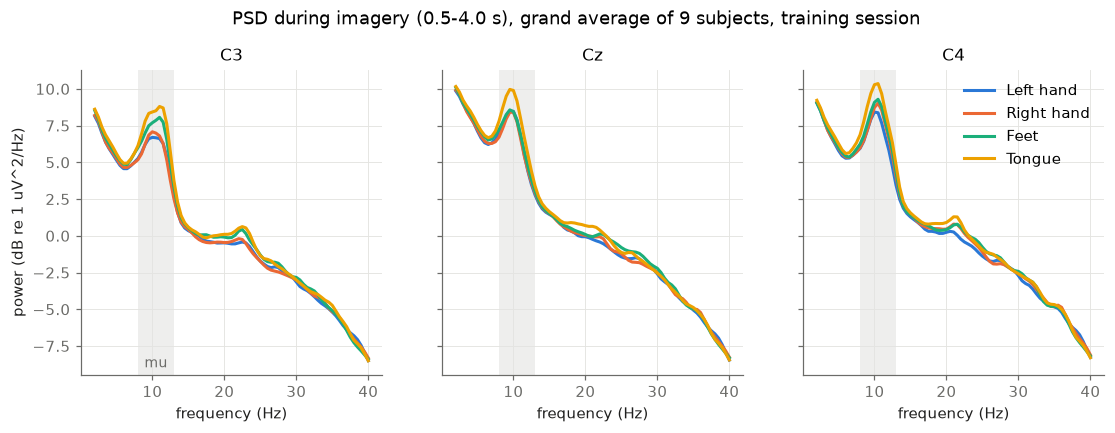

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, ch in zip(axes, ["C3", "Cz", "C4"]):
    ci = ch_names.index(ch)
    for cls in CLASSES:
        ax.plot(psd_freqs, 10 * np.log10(ga_psd[cls][ci] * 1e12), color=COLORS[cls], label=LABELS[cls])
    ax.axvspan(8, 13, color=GRID, alpha=0.6, lw=0)
    ax.set_title(ch); ax.set_xlabel("frequency (Hz)")
axes[0].set_ylabel("power (dB re 1 uV^2/Hz)")
axes[0].text(10.5, axes[0].get_ylim()[0] + 0.5, "mu", ha="center", color=MUTED, fontsize=9)
axes[-1].legend(loc="upper right")
fig.suptitle("PSD during imagery (0.5-4.0 s), grand average of 9 subjects, training session", y=1.03)
fig.savefig(FIG / "eda_psd_by_class.png")
plt.show()

## 6. Event-related (de)synchronization: ERD / ERS

**ERD** (event-related desynchronization) is a *decrease* in oscillatory power
relative to a rest baseline; **ERS** (synchronization) is an *increase*. When a
cortical area becomes active (moving, or imagining moving, a body part), its
neurons stop firing in synchrony, so the large mu (8-13 Hz) and beta (13-30 Hz)
rhythms over that area shrink: an ERD. After the movement ends, beta power often
overshoots above baseline: the "beta rebound", an ERS.

Below: `ERD% = (P(t, f) - P_baseline(f)) / P_baseline(f) x 100`, baseline
-1.5 to -0.5 s, Morlet wavelets, computed per subject and then averaged.
Blue = power decrease (ERD), red = increase (ERS).

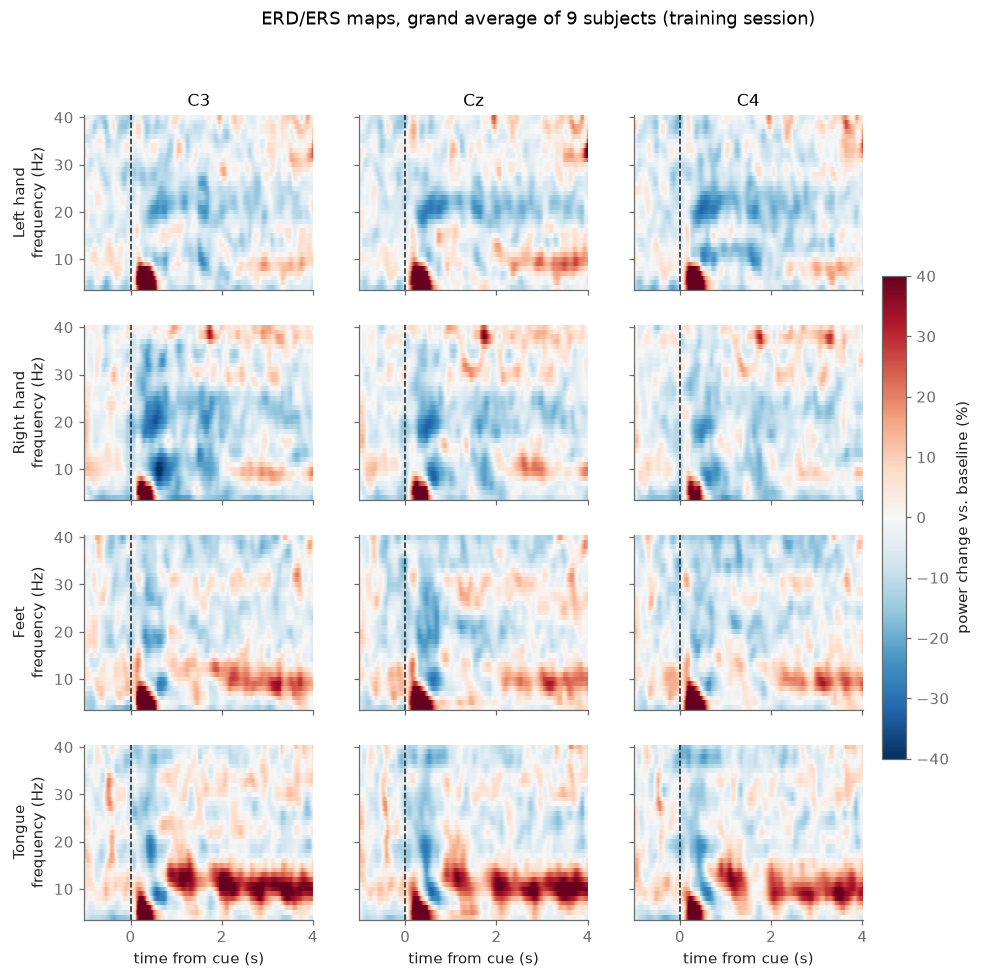

In [7]:
vlim = 40
show = (tfr_times >= -1.0) & (tfr_times <= 4.0)
fig, axes = plt.subplots(len(CLASSES), 3, figsize=(11, 9.5), sharex=True, sharey=True)
for r, cls in enumerate(CLASSES):
    for c, ch in enumerate(["C3", "Cz", "C4"]):
        ax = axes[r, c]
        ci = ch_names.index(ch)
        im = ax.pcolormesh(tfr_times[show], FREQS, ga_tfr[cls][ci][:, show],
                           cmap="RdBu_r", vmin=-vlim, vmax=vlim, shading="auto")
        ax.axvline(0, color=INK, lw=1, ls="--")
        ax.grid(False)
        if r == 0: ax.set_title(ch)
        if c == 0: ax.set_ylabel(f"{LABELS[cls]}\nfrequency (Hz)")
        if r == len(CLASSES) - 1: ax.set_xlabel("time from cue (s)")
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02)
cb.set_label("power change vs. baseline (%)")
fig.suptitle("ERD/ERS maps, grand average of 9 subjects (training session)")
fig.savefig(FIG / "eda_erd_tfr.png")
plt.show()

### Why C3 and C4 separate left from right hand

Motor control is **contralateral**: the left hemisphere controls the right hand
and vice-versa. Imagining a right-hand movement should therefore produce a
stronger mu/beta ERD over the *left* motor cortex (**C3**) than over the right
(**C4**), and the opposite for the left hand. This hemispheric asymmetry is the
main feature a left-vs-right decoder can exploit. Feet are represented near the
midline (Cz), and tongue more laterally and lower, closer to the edges of this
montage, which is one reason feet vs. tongue is usually harder to separate.

The band-power time courses make the asymmetry easier to read than the maps.

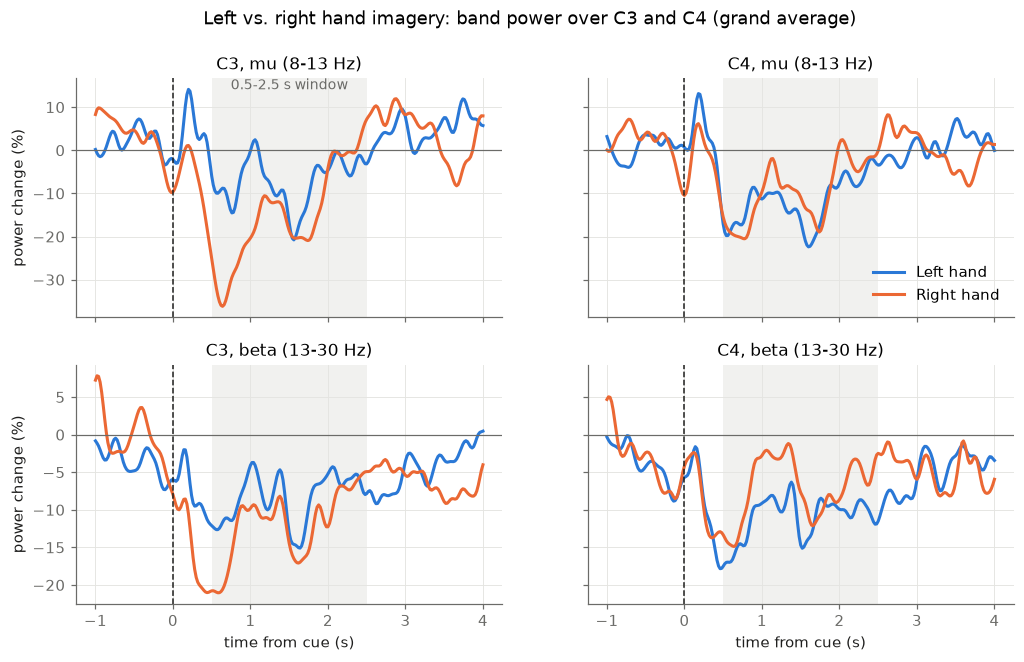

C3 mu, Left hand : min  -20.8% at 1.56 s, mean 0.5-2.5 s   -7.2%
C3 mu, Right hand: min  -36.2% at 0.64 s, mean 0.5-2.5 s  -14.8%
C4 mu, Left hand : min  -22.4% at 1.60 s, mean 0.5-2.5 s  -11.8%
C4 mu, Right hand: min  -20.5% at 0.78 s, mean 0.5-2.5 s   -9.6%


In [8]:
def band_course(cls, ch, lo, hi):
    fi = (FREQS >= lo) & (FREQS <= hi)
    return ga_tfr[cls][ch_names.index(ch)][fi].mean(axis=0)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.2), sharex=True, sharey="row")
for r, (band, lo, hi) in enumerate([("mu", 8, 13), ("beta", 13, 30)]):
    for c, ch in enumerate(["C3", "C4"]):
        ax = axes[r, c]
        for cls in ["left_hand", "right_hand"]:
            ax.plot(tfr_times[show], band_course(cls, ch, lo, hi)[show], color=COLORS[cls], label=LABELS[cls])
        ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=INK, lw=1, ls="--")
        ax.axvspan(0.5, 2.5, color=GRID, alpha=0.5, lw=0)
        ax.set_title(f"{ch}, {band} ({lo}-{hi} Hz)")
        if c == 0: ax.set_ylabel("power change (%)")
        if r == 1: ax.set_xlabel("time from cue (s)")
axes[0, 1].legend(loc="lower right")
axes[0, 0].text(1.5, axes[0, 0].get_ylim()[1] * 0.85, "0.5-2.5 s window", ha="center", color=MUTED, fontsize=9)
fig.suptitle("Left vs. right hand imagery: band power over C3 and C4 (grand average)")
fig.savefig(FIG / "eda_erd_timecourse.png")
plt.show()

in_win = (tfr_times >= 0.5) & (tfr_times <= 2.5)
for ch in ["C3", "C4"]:
    for cls in ["left_hand", "right_hand"]:
        c = band_course(cls, ch, 8, 13)
        print(f"{ch} mu, {LABELS[cls]:<10}: min {c[in_win].min():6.1f}% at {tfr_times[in_win][c[in_win].argmin()]:.2f} s, "
              f"mean 0.5-2.5 s {c[in_win].mean():6.1f}%")

### Spatial distribution of the mu ERD

Mean mu-band (8-13 Hz) power change between 0.5 and 2.5 s after the cue, per
class, grand average.

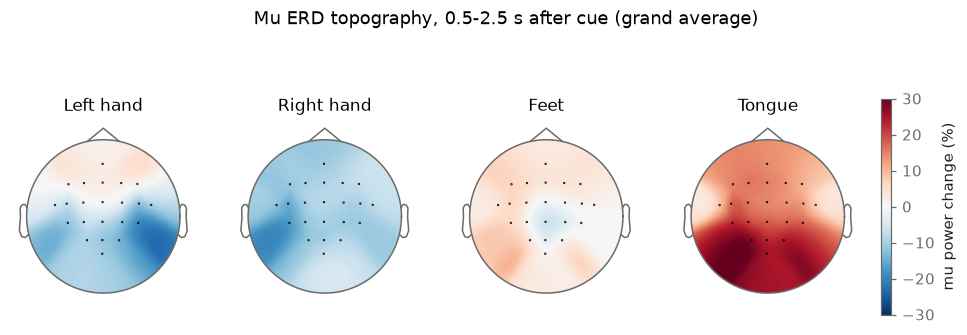

In [9]:
mu = (FREQS >= 8) & (FREQS <= 13)
win_t = (tfr_times >= 0.5) & (tfr_times <= 2.5)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, cls in zip(axes, CLASSES):
    vals = ga_tfr[cls][:, mu][:, :, win_t].mean(axis=(1, 2))
    im, _ = mne.viz.plot_topomap(vals, info, axes=ax, show=False, cmap="RdBu_r",
                                 vlim=(-30, 30), contours=0, sensors=True)
    ax.set_title(LABELS[cls])
cb = fig.colorbar(im, ax=axes, shrink=0.75, pad=0.02)
cb.set_label("mu power change (%)")
fig.suptitle("Mu ERD topography, 0.5-2.5 s after cue (grand average)", y=1.02)
fig.savefig(FIG / "eda_erd_topomaps.png")
plt.show()

## 7. Subject variability

Grand averages hide how different subjects are. For each subject, the
lateralization of the mu ERD (0.5-2.5 s):

- `C3 effect = ERD(C3 | right hand) - ERD(C3 | left hand)`, expected < 0
- `C4 effect = ERD(C4 | left hand) - ERD(C4 | right hand)`, expected < 0

A clearly negative value means the expected contralateral pattern is present.

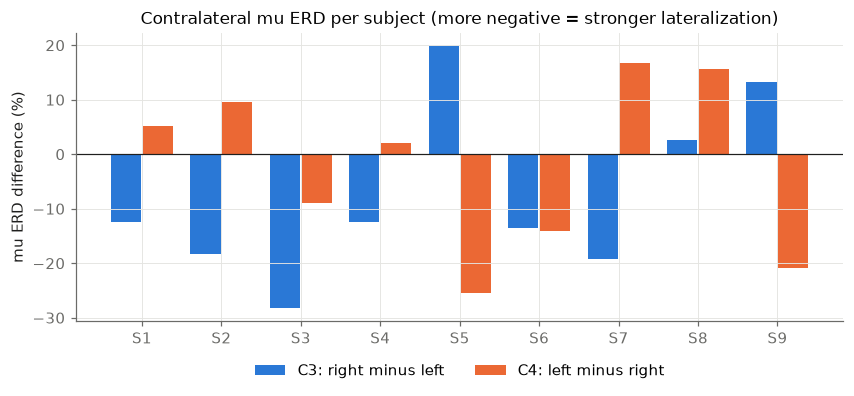

,C3 effect (%),C4 effect (%)
subject,,
1,-12.4,5.1
2,-18.4,9.6
3,-28.2,-9.0
4,-12.5,2.1
5,19.8,-25.5
6,-13.6,-14.1
7,-19.3,16.8
8,2.7,15.7
9,13.2,-20.9


In [10]:
def subj_mu(s_idx, cls, ch):
    t = np.asarray(tfr_by_class[cls][s_idx]) * 100
    return t[ch_names.index(ch)][mu][:, win_t].mean()

rows = []
for i, s in enumerate(SUBJECTS):
    rows.append({
        "subject": s,
        "C3 effect (%)": subj_mu(i, "right_hand", "C3") - subj_mu(i, "left_hand", "C3"),
        "C4 effect (%)": subj_mu(i, "left_hand", "C4") - subj_mu(i, "right_hand", "C4"),
    })
lat = pd.DataFrame(rows).set_index("subject")
lat.to_csv(ROOT / "results" / "eda_mu_lateralization.csv", float_format="%.2f")

fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(SUBJECTS)); w = 0.38
ax.bar(x - w / 2 - 0.01, lat["C3 effect (%)"], w, color="#2a78d6", label="C3: right minus left")
ax.bar(x + w / 2 + 0.01, lat["C4 effect (%)"], w, color="#eb6834", label="C4: left minus right")
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(x, [f"S{s}" for s in SUBJECTS]); ax.set_ylabel("mu ERD difference (%)")
ax.set_title("Contralateral mu ERD per subject (more negative = stronger lateralization)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=2)
fig.savefig(FIG / "eda_mu_lateralization_per_subject.png")
plt.show()
lat.round(1)

## 8. What the data shows, and what it means for modelling

1. **The cue itself produces a strong, class-independent response.** In every
   class and channel there is a large power increase below ~8 Hz during the
   first 0.5 s after the cue: the visual evoked response to the arrow. It
   carries no information about the imagined movement, which is the reason to
   **start the decoding window at 0.5 s**.
2. **Hand imagery = ERD, feet/tongue imagery = ERS over the hand areas.** Left-
   and right-hand imagery decrease mu/beta power. Feet and, even more, tongue
   imagery *increase* mu power over C3/C4 from ~1 s onwards. This is the "focal
   ERD / surround ERS" pattern described by Pfurtscheller: activating one body
   representation is accompanied by idling (synchronization) of neighbouring
   ones. Both effects live in **mu and beta**, which supports **8-30 Hz for
   CSP**; the deep models get 4-40 Hz and learn their own filters.
3. **The two patterns have different time courses.** The hand ERD at C3 peaks
   around 0.5-1.0 s and is largely gone by ~2 s, while the feet/tongue ERS
   builds after 1 s and lasts until the end of the trial. The planned
   **0.5-2.5 s** window captures the hand ERD well but only part of the ERS; a
   longer window (0.5-4.0 s) may help separate feet from tongue. That is a
   cheap ablation to run once the pipelines exist.
4. **Lateralization is weaker and less consistent than the textbook picture.**
   In the grand average, mu power over C3 during 0.5-2.5 s drops by 14.8% for
   right-hand imagery vs. 7.2% for left-hand imagery (the right-hand ERD peaks
   at -36% around 0.6 s). Over C4 the expected difference is much smaller:
   11.8% (left) vs. 9.6% (right). Per subject (section 7), the expected C3 effect appears in
   6 of 9 subjects and the C4 effect in 4 of 9; only subjects 3 and 6 show
   both. In the topographies the strongest hand ERD is slightly posterior to
   C3/C4 (around CP3/CP4). Hand-picking C3/C4 would throw information away;
   **learned spatial filters over all 22 channels** (CSP, EEGNet's depthwise
   convolution) are the right tool.
5. **Subject variability is large**, so results must be reported per subject,
   not only as a mean, and n = 9 limits any statistical claim.